## Terceira lista de simulação: agrupamento de dados

## Bruno Victor Paiva da Silva - 2026006269

### Analise o desempenho dos algoritmos Hierárquico, K-Means, GMM e DBSCAN para agrupar dados na base de dados Dígitos.

### Analise a influência dos hiperparâmetros dos algoritmos.

###

In [3]:
from sklearn import datasets
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

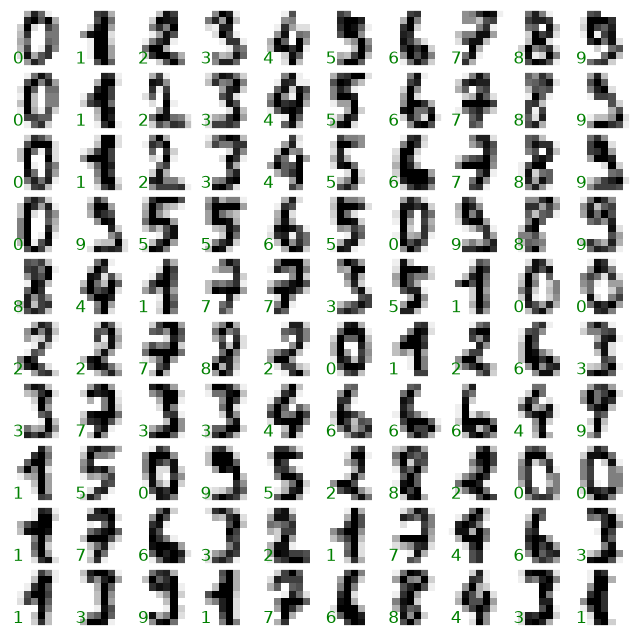

In [4]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.images.shape

fig, axes = plt.subplots(10, 10, figsize=(8, 8), subplot_kw={'xticks':[], 'yticks':[]}, gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i, ax in enumerate(axes.flat):
  ax.imshow(digits.images[i], cmap='binary', interpolation='nearest')
  ax.text(0.05, 0.05, str(digits.target[i]),transform=ax.transAxes, color='green')

In [5]:
X = digits.data
X.shape

(1797, 64)

In [6]:
y = digits.target
y.shape

(1797,)

In [7]:
X = digits.data
y = digits.target
print(X.shape)
print(y.shape)

(1797, 64)
(1797,)


## Importação das métricas

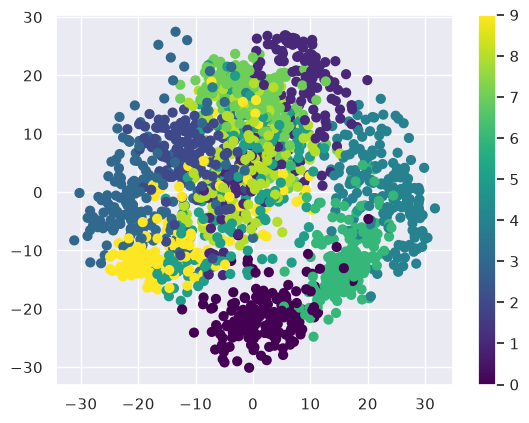

In [8]:
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.metrics.cluster import adjusted_mutual_info_score
from sklearn.metrics.cluster import homogeneity_score
from sklearn.metrics.cluster import completeness_score
from sklearn.metrics.cluster import silhouette_score

def avalia(nome, X, y, clusters):
  print("{} - ARI: {:.2f}".format(nome, adjusted_rand_score(y, clusters)))
  print("{} - MIS: {:.2f}".format(nome, adjusted_mutual_info_score(y, clusters)))
  print("{} - Homogeneity: {:.2f}".format(nome, homogeneity_score(y, clusters)))
  print("{} - Completeness: {:.2f}".format(nome, completeness_score(y, clusters)))
  if len(set(clusters)) > 1:    
    print("{} - Silhouette: {:.2f}".format(nome, silhouette_score(X, clusters)))
  else:
    print("{} - Silhouette: não definido (apenas 1 grupo)".format(nome))
  print()

from sklearn.decomposition import PCA
X_pca = PCA(n_components=2).fit_transform(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=40, cmap='viridis')
plt.colorbar()

## Algoritmo Hierárquico Aglomerativo

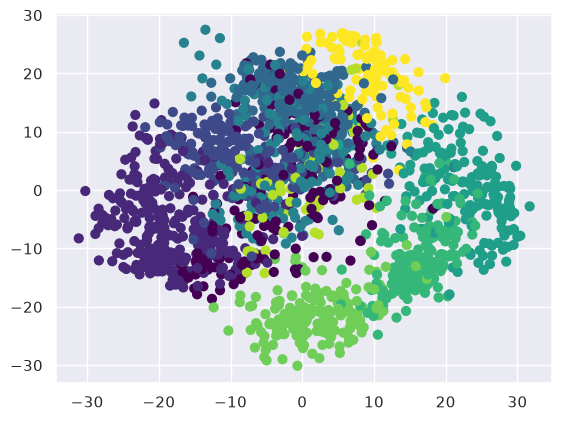

In [9]:
from sklearn.cluster import AgglomerativeClustering              

hierarquico = AgglomerativeClustering(n_clusters = 10)            

y_h = hierarquico.fit_predict(X)                                 

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_h, s=40, cmap='viridis')

In [10]:
hierarquico

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",10
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_sample

In [11]:
avalia("AgglomerativeClustering", X, y, y_h)

AgglomerativeClustering - ARI: 0.79
AgglomerativeClustering - MIS: 0.87
AgglomerativeClustering - Homogeneity: 0.86
AgglomerativeClustering - Completeness: 0.88
AgglomerativeClustering - Silhouette: 0.18



linkage = ward - ARI: 0.79
linkage = ward - MIS: 0.87
linkage = ward - Homogeneity: 0.86
linkage = ward - Completeness: 0.88
linkage = ward - Silhouette: 0.18

linkage = complete - ARI: 0.43
linkage = complete - MIS: 0.61
linkage = complete - Homogeneity: 0.59
linkage = complete - Completeness: 0.64
linkage = complete - Silhouette: 0.12

linkage = average - ARI: 0.51
linkage = average - MIS: 0.71
linkage = average - Homogeneity: 0.66
linkage = average - Completeness: 0.78
linkage = average - Silhouette: 0.15

linkage = single - ARI: 0.00
linkage = single - MIS: 0.00
linkage = single - Homogeneity: 0.01
linkage = single - Completeness: 0.27
linkage = single - Silhouette: -0.13



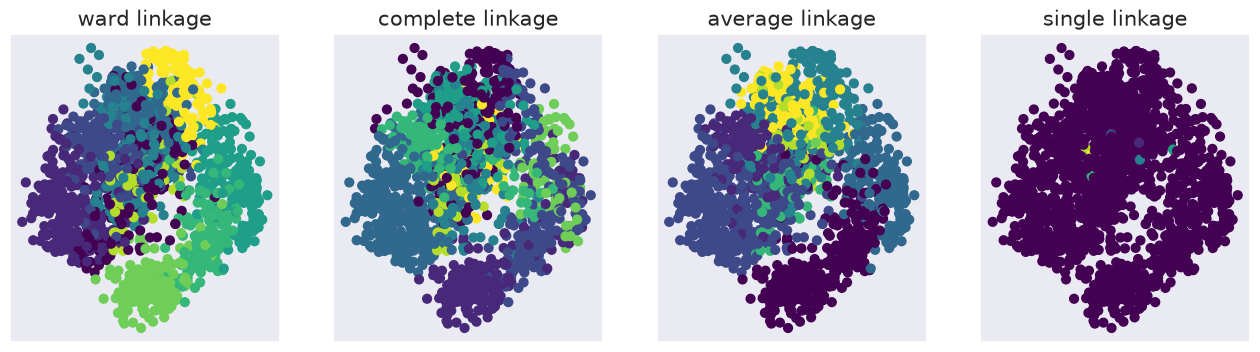

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), subplot_kw={'xticks': (), 'yticks': ()})

for ax, linkage in zip(axes, ('ward', 'complete', 'average', 'single')):
  clustering = AgglomerativeClustering(linkage = linkage, n_clusters = 10)
  clusters = clustering.fit_predict(X)
  ax.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, s=40, cmap='viridis')
  ax.set_title(linkage + " linkage", size = 15)
  avalia("linkage = " + linkage, X, y, clusters)

In [13]:
for n in (2, 5, 8, 10, 12, 15, 20):
  clusters = AgglomerativeClustering(n_clusters = n).fit_predict(X)
  avalia("n_clusters = {}".format(n), X, y, clusters)

n_clusters = 2 - ARI: 0.15
n_clusters = 2 - MIS: 0.41
n_clusters = 2 - Homogeneity: 0.26
n_clusters = 2 - Completeness: 0.97
n_clusters = 2 - Silhouette: 0.12

n_clusters = 5 - ARI: 0.49
n_clusters = 5 - MIS: 0.71
n_clusters = 5 - Homogeneity: 0.59
n_clusters = 5 - Completeness: 0.88
n_clusters = 5 - Silhouette: 0.12

n_clusters = 8 - ARI: 0.73
n_clusters = 8 - MIS: 0.84
n_clusters = 8 - Homogeneity: 0.80
n_clusters = 8 - Completeness: 0.90
n_clusters = 8 - Silhouette: 0.17

n_clusters = 10 - ARI: 0.79
n_clusters = 10 - MIS: 0.87
n_clusters = 10 - Homogeneity: 0.86
n_clusters = 10 - Completeness: 0.88
n_clusters = 10 - Silhouette: 0.18

n_clusters = 12 - ARI: 0.81
n_clusters = 12 - MIS: 0.87
n_clusters = 12 - Homogeneity: 0.89
n_clusters = 12 - Completeness: 0.84
n_clusters = 12 - Silhouette: 0.17

n_clusters = 15 - ARI: 0.74
n_clusters = 15 - MIS: 0.84
n_clusters = 15 - Homogeneity: 0.90
n_clusters = 15 - Completeness: 0.78
n_clusters = 15 - Silhouette: 0.18

n_clusters = 20 - ARI: 0.

## Algoritmos K-Means

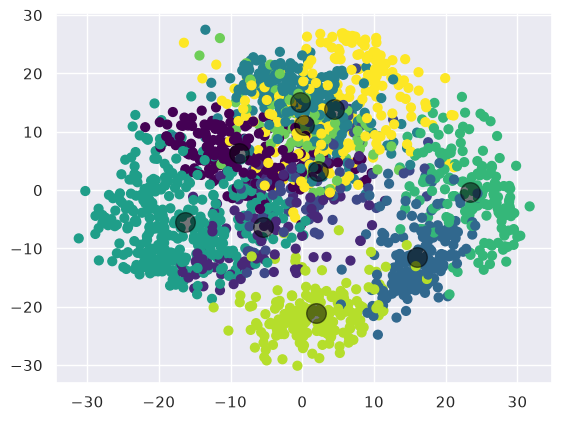

In [14]:
from sklearn.cluster import KMeans        

kmeans = KMeans(n_clusters=10, random_state=0)   
kmeans.fit(X)                                    
y_kmeans = kmeans.predict(X)                     


plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, s=40, cmap='viridis')

centers = PCA(n_components=2).fit(X).transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

In [15]:
kmeans

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 64)",

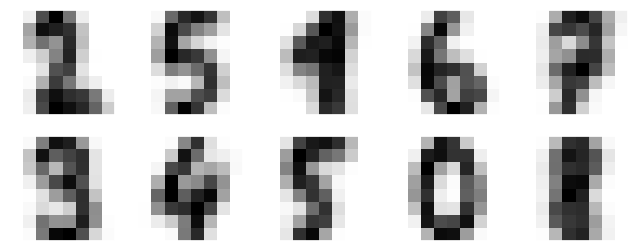

In [16]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3), subplot_kw={'xticks':[], 'yticks':[]})
centers_img = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers_img):
  axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [17]:
avalia("KMeans", X, y, y_kmeans)

KMeans - ARI: 0.62
KMeans - MIS: 0.73
KMeans - Homogeneity: 0.72
KMeans - Completeness: 0.75
KMeans - Silhouette: 0.19



In [18]:
for n in (5, 8, 10, 12, 15):
  clusters = KMeans(n_clusters=n, random_state=0).fit_predict(X)
  avalia("n_clusters = {}".format(n), X, y, clusters)

n_clusters = 5 - ARI: 0.32
n_clusters = 5 - MIS: 0.49
n_clusters = 5 - Homogeneity: 0.41
n_clusters = 5 - Completeness: 0.61
n_clusters = 5 - Silhouette: 0.13

n_clusters = 8 - ARI: 0.51
n_clusters = 8 - MIS: 0.67
n_clusters = 8 - Homogeneity: 0.62
n_clusters = 8 - Completeness: 0.72
n_clusters = 8 - Silhouette: 0.18

n_clusters = 10 - ARI: 0.62
n_clusters = 10 - MIS: 0.73
n_clusters = 10 - Homogeneity: 0.72
n_clusters = 10 - Completeness: 0.75
n_clusters = 10 - Silhouette: 0.19

n_clusters = 12 - ARI: 0.65
n_clusters = 12 - MIS: 0.75
n_clusters = 12 - Homogeneity: 0.77
n_clusters = 12 - Completeness: 0.74
n_clusters = 12 - Silhouette: 0.18

n_clusters = 15 - ARI: 0.58
n_clusters = 15 - MIS: 0.74
n_clusters = 15 - Homogeneity: 0.79
n_clusters = 15 - Completeness: 0.70
n_clusters = 15 - Silhouette: 0.17



In [19]:
for mi in (1, 2, 5, 7, 10):
  clusters = KMeans(n_clusters=10, max_iter=mi, n_init=1, random_state=0).fit_predict(X)
  avalia("max_iter = {}".format(mi), X, y, clusters)

max_iter = 1 - ARI: 0.62
max_iter = 1 - MIS: 0.71
max_iter = 1 - Homogeneity: 0.70
max_iter = 1 - Completeness: 0.72
max_iter = 1 - Silhouette: 0.17

max_iter = 2 - ARI: 0.64
max_iter = 2 - MIS: 0.73
max_iter = 2 - Homogeneity: 0.72
max_iter = 2 - Completeness: 0.74
max_iter = 2 - Silhouette: 0.18

max_iter = 5 - ARI: 0.62
max_iter = 5 - MIS: 0.72
max_iter = 5 - Homogeneity: 0.72
max_iter = 5 - Completeness: 0.73
max_iter = 5 - Silhouette: 0.18

max_iter = 7 - ARI: 0.62
max_iter = 7 - MIS: 0.72
max_iter = 7 - Homogeneity: 0.71
max_iter = 7 - Completeness: 0.73
max_iter = 7 - Silhouette: 0.18

max_iter = 10 - ARI: 0.61
max_iter = 10 - MIS: 0.72
max_iter = 10 - Homogeneity: 0.71
max_iter = 10 - Completeness: 0.73
max_iter = 10 - Silhouette: 0.18



In [20]:
for init in ('k-means++', 'random'):
  clusters = KMeans(n_clusters=10, init=init, n_init=10, random_state=0).fit_predict(X)
  avalia("init = " + init, X, y, clusters)

init = k-means++ - ARI: 0.67
init = k-means++ - MIS: 0.74
init = k-means++ - Homogeneity: 0.74
init = k-means++ - Completeness: 0.75
init = k-means++ - Silhouette: 0.18

init = random - ARI: 0.66
init = random - MIS: 0.73
init = random - Homogeneity: 0.73
init = random - Completeness: 0.74
init = random - Silhouette: 0.18



## Algoritmo GMM - Gaussian Mixture Models

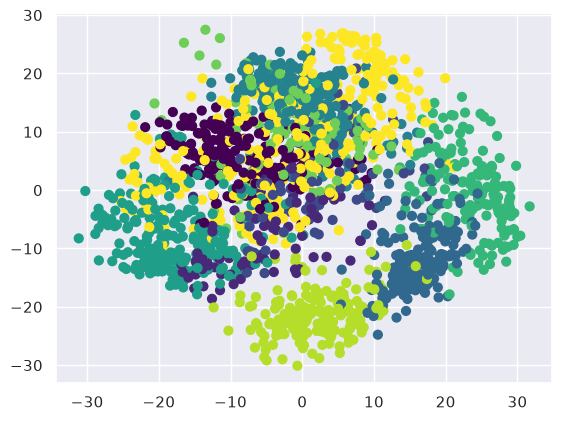

In [21]:
from sklearn.mixture import GaussianMixture                                  
gmm = GaussianMixture(n_components=10, covariance_type='full', random_state=0).fit(X)   
labels_gmm = gmm.predict(X)                                                  

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, s=40, cmap='viridis');

In [22]:
gmm

,"n_components n_components: int, default=1The number of mixture components.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


[[0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]


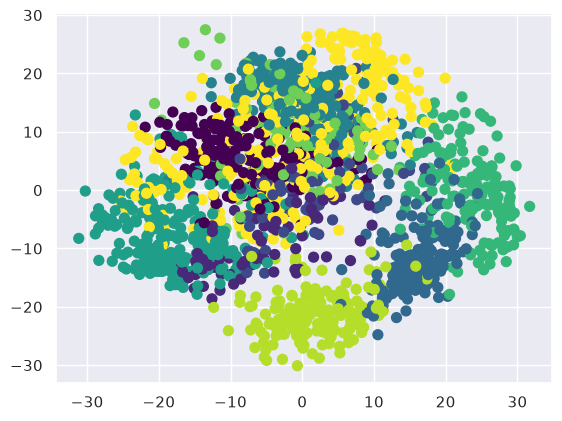

In [23]:
probs = gmm.predict_proba(X)
print(probs[:5].round(3))

size = 50 * probs.max(1) ** 2
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap='viridis', s=size);

In [24]:
avalia("GaussianMixture", X, y, labels_gmm)

GaussianMixture - ARI: 0.61
GaussianMixture - MIS: 0.73
GaussianMixture - Homogeneity: 0.72
GaussianMixture - Completeness: 0.74
GaussianMixture - Silhouette: 0.17



In [25]:
for ct in ('full', 'tied', 'diag', 'spherical'):
  clusters = GaussianMixture(n_components=10, covariance_type=ct, random_state=0).fit_predict(X)
  avalia("covariance_type = " + ct, X, y, clusters)

covariance_type = full - ARI: 0.61
covariance_type = full - MIS: 0.73
covariance_type = full - Homogeneity: 0.72
covariance_type = full - Completeness: 0.74
covariance_type = full - Silhouette: 0.17

covariance_type = tied - ARI: 0.63
covariance_type = tied - MIS: 0.76
covariance_type = tied - Homogeneity: 0.75
covariance_type = tied - Completeness: 0.78
covariance_type = tied - Silhouette: 0.18

covariance_type = diag - ARI: 0.52
covariance_type = diag - MIS: 0.63
covariance_type = diag - Homogeneity: 0.62
covariance_type = diag - Completeness: 0.64
covariance_type = diag - Silhouette: 0.13

covariance_type = spherical - ARI: 0.59
covariance_type = spherical - MIS: 0.72
covariance_type = spherical - Homogeneity: 0.71
covariance_type = spherical - Completeness: 0.74
covariance_type = spherical - Silhouette: 0.18



In [26]:
for n in (5, 8, 10, 12, 15):
  clusters = GaussianMixture(n_components=n, covariance_type='full', random_state=0).fit_predict(X)
  avalia("n_components = {}".format(n), X, y, clusters)

n_components = 5 - ARI: 0.32
n_components = 5 - MIS: 0.55
n_components = 5 - Homogeneity: 0.45
n_components = 5 - Completeness: 0.71
n_components = 5 - Silhouette: 0.10

n_components = 8 - ARI: 0.51
n_components = 8 - MIS: 0.65
n_components = 8 - Homogeneity: 0.61
n_components = 8 - Completeness: 0.70
n_components = 8 - Silhouette: 0.16

n_components = 10 - ARI: 0.61
n_components = 10 - MIS: 0.73
n_components = 10 - Homogeneity: 0.72
n_components = 10 - Completeness: 0.74
n_components = 10 - Silhouette: 0.17

n_components = 12 - ARI: 0.61
n_components = 12 - MIS: 0.73
n_components = 12 - Homogeneity: 0.75
n_components = 12 - Completeness: 0.72
n_components = 12 - Silhouette: 0.15

n_components = 15 - ARI: 0.51
n_components = 15 - MIS: 0.71
n_components = 15 - Homogeneity: 0.74
n_components = 15 - Completeness: 0.68
n_components = 15 - Silhouette: 0.14



## Algoritmo DBSCAN

Cluster memberships:
[-1 -1 -1 ... -1 -1 -1]


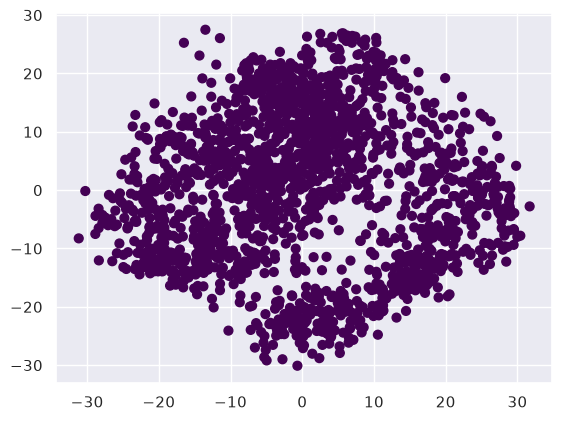

In [27]:
from sklearn.cluster import DBSCAN                               
dbscan = DBSCAN()                                                
labels_dbscan = dbscan.fit_predict(X)                            

print("Cluster memberships:\n{}".format(labels_dbscan))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_dbscan, s=40, cmap='viridis');

In [28]:
dbscan

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.5
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](0, 64)",[]
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](0,)",[]


In [29]:
for eps in (10, 15, 20, 25, 30):
  for ms in (5, 10):
    clusters = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    print("eps = {}, min_samples = {} -> {} clusters, {} pontos de ruído".format(
        eps, ms, len(set(clusters)) - (1 if -1 in clusters else 0), np.sum(clusters == -1)))
    avalia("DBSCAN(eps={}, min_samples={})".format(eps, ms), X, y, clusters)

eps = 10, min_samples = 5 -> 0 clusters, 1797 pontos de ruído
DBSCAN(eps=10, min_samples=5) - ARI: 0.00
DBSCAN(eps=10, min_samples=5) - MIS: 0.00
DBSCAN(eps=10, min_samples=5) - Homogeneity: 0.00
DBSCAN(eps=10, min_samples=5) - Completeness: 1.00
DBSCAN(eps=10, min_samples=5) - Silhouette: não definido (apenas 1 grupo)

eps = 10, min_samples = 10 -> 0 clusters, 1797 pontos de ruído
DBSCAN(eps=10, min_samples=10) - ARI: 0.00
DBSCAN(eps=10, min_samples=10) - MIS: 0.00
DBSCAN(eps=10, min_samples=10) - Homogeneity: 0.00
DBSCAN(eps=10, min_samples=10) - Completeness: 1.00
DBSCAN(eps=10, min_samples=10) - Silhouette: não definido (apenas 1 grupo)

eps = 15, min_samples = 5 -> 16 clusters, 1553 pontos de ruído
DBSCAN(eps=15, min_samples=5) - ARI: 0.01
DBSCAN(eps=15, min_samples=5) - MIS: 0.19
DBSCAN(eps=15, min_samples=5) - Homogeneity: 0.14
DBSCAN(eps=15, min_samples=5) - Completeness: 0.46
DBSCAN(eps=15, min_samples=5) - Silhouette: -0.23

eps = 15, min_samples = 10 -> 3 clusters, 1726 pont

DBSCAN(eps=20, min_samples=5) - ARI: 0.47
DBSCAN(eps=20, min_samples=5) - MIS: 0.71
DBSCAN(eps=20, min_samples=5) - Homogeneity: 0.75
DBSCAN(eps=20, min_samples=5) - Completeness: 0.68
DBSCAN(eps=20, min_samples=5) - Silhouette: 0.07



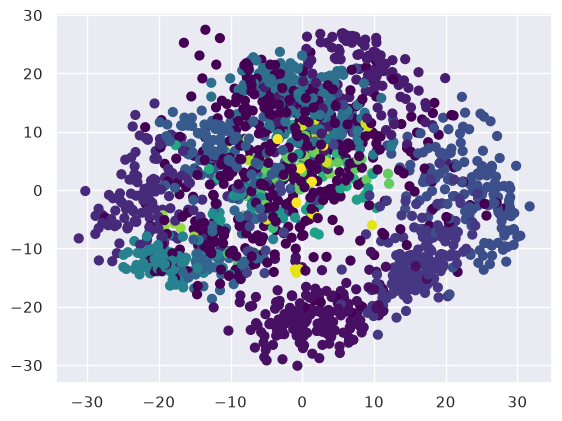

In [30]:
dbscan = DBSCAN(eps=20, min_samples=5)
labels_dbscan = dbscan.fit_predict(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_dbscan, s=40, cmap='viridis');
avalia("DBSCAN(eps=20, min_samples=5)", X, y, labels_dbscan)

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

for eps in (3, 5, 7, 10):
  clusters = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
  print("eps = {} -> {} clusters, {} pontos de ruído".format(
      eps, len(set(clusters)) - (1 if -1 in clusters else 0), np.sum(clusters == -1)))
  avalia("DBSCAN normalizado (eps={})".format(eps), X_scaled, y, clusters)

eps = 3 -> 13 clusters, 1618 pontos de ruído
DBSCAN normalizado (eps=3) - ARI: 0.01
DBSCAN normalizado (eps=3) - MIS: 0.15
DBSCAN normalizado (eps=3) - Homogeneity: 0.10
DBSCAN normalizado (eps=3) - Completeness: 0.44
DBSCAN normalizado (eps=3) - Silhouette: -0.23

eps = 5 -> 4 clusters, 207 pontos de ruído
DBSCAN normalizado (eps=5) - ARI: 0.00
DBSCAN normalizado (eps=5) - MIS: 0.04
DBSCAN normalizado (eps=5) - Homogeneity: 0.03
DBSCAN normalizado (eps=5) - Completeness: 0.14
DBSCAN normalizado (eps=5) - Silhouette: -0.01

eps = 7 -> 2 clusters, 34 pontos de ruído
DBSCAN normalizado (eps=7) - ARI: 0.00
DBSCAN normalizado (eps=7) - MIS: 0.01
DBSCAN normalizado (eps=7) - Homogeneity: 0.01
DBSCAN normalizado (eps=7) - Completeness: 0.13
DBSCAN normalizado (eps=7) - Silhouette: 0.27

eps = 10 -> 1 clusters, 17 pontos de ruído
DBSCAN normalizado (eps=10) - ARI: 0.00
DBSCAN normalizado (eps=10) - MIS: 0.00
DBSCAN normalizado (eps=10) - Homogeneity: 0.00
DBSCAN normalizado (eps=10) - Complet

## Comparação entre os 4 algoritmos

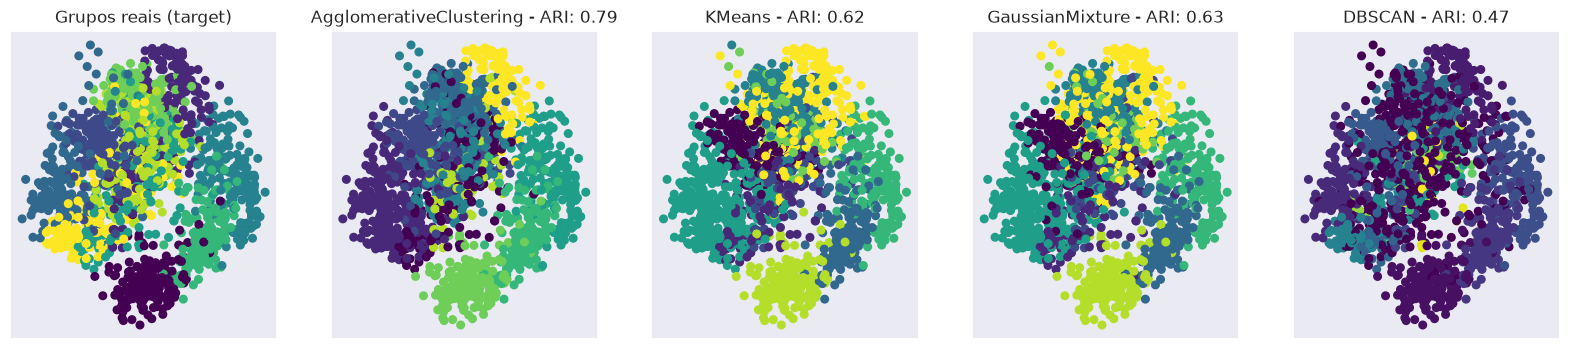

In [32]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN

fig, axes = plt.subplots(1, 5, figsize=(20, 4), subplot_kw={'xticks': (), 'yticks': ()})

algorithms = [AgglomerativeClustering(n_clusters=10, linkage='ward'), KMeans(n_clusters=10, random_state=0),
              GaussianMixture(n_components=10, covariance_type='tied', random_state=0), DBSCAN(eps=20, min_samples=5)]

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=30)
axes[0].set_title("Grupos reais (target)")

for ax, algorithm in zip(axes[1:], algorithms):
  clusters = algorithm.fit_predict(X)
  ax.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=30)
  ax.set_title("{} - ARI: {:.2f}".format(algorithm.__class__.__name__, adjusted_rand_score(y, clusters)))

In [33]:
for algorithm in algorithms:
  clusters = algorithm.fit_predict(X)
  avalia(algorithm.__class__.__name__, X, y, clusters)

AgglomerativeClustering - ARI: 0.79
AgglomerativeClustering - MIS: 0.87
AgglomerativeClustering - Homogeneity: 0.86
AgglomerativeClustering - Completeness: 0.88
AgglomerativeClustering - Silhouette: 0.18

KMeans - ARI: 0.62
KMeans - MIS: 0.73
KMeans - Homogeneity: 0.72
KMeans - Completeness: 0.75
KMeans - Silhouette: 0.19

GaussianMixture - ARI: 0.63
GaussianMixture - MIS: 0.76
GaussianMixture - Homogeneity: 0.75
GaussianMixture - Completeness: 0.78
GaussianMixture - Silhouette: 0.18

DBSCAN - ARI: 0.47
DBSCAN - MIS: 0.71
DBSCAN - Homogeneity: 0.75
DBSCAN - Completeness: 0.68
DBSCAN - Silhouette: 0.07

